In [1]:
import Network_lib as nl
import pandas as pd
import Lightning_lib as ls

from Network_lib.Node import PhaseName

In [2]:
class Trf_parameters():
        def __init__(self,A,B,C,D):
            self.CapHV=A
            self.CapHL=B
            self.CapLV=C
            self.Ground=D

In [3]:
def data_setting():
    #Definition Nodes
    #id of the node must be integer or string of maximum 4 characters, preferably integer, label is the name of the node, x and y are the coordinates in meters from the initial location defined in the network_setting function, if ctype is "rel" the coordinates are relative to the initial location, if ctype is "abs" the coordinates are absolute from the initial location
    Nodes = pd.DataFrame(columns=['id', 'label','y','x'])
    Nodes.loc[0] = [1, 'N1', 125300, 103000]
    Nodes.loc[1] = [2, 'N2', 125450, 103050]
    Nodes.loc[2] = [3, 'N3', 125500, 103100]
    Nodes.loc[3] = [4, 'N4', 125650, 103150]

    #Definition Lines
    "from_node to to_node must be the id of the nodes defined in the Nodes dataframe, configuration_type must be one of the configurations defined in the network_setting function"
    Lines=pd.DataFrame(columns=['id', 'label', 'from_node', 'to_node','configuration_type'])
    Lines.loc[0] = [1, 'L1', 'N1', 'N2','Config_A']
    Lines.loc[1] = [2, 'L2', 'N2', 'N3','Config_A']
    Lines.loc[2] = [3, 'L3', 'N3', 'N4','Config_B']

    #Definition high frequency transformer types
    
    Tr1= Trf_parameters(340e-12, 744e-12, 215e-12, 10)
    Tr2= Trf_parameters(440e-12, 644e-12, 115e-12, 20)

    #Transformers connections
    Transformers=pd.DataFrame(columns=['id', 'label', 'from_node', 'phases','trf_type'])
    Transformers.loc[0] = [1, 'T1', 'N2', 111,'Tr1']
    Transformers.loc[1] = [2, 'T2', 'N1', 11,'Tr2']
    Transformers.loc[2] = [3, 'T3', 'N3', 101,'Tr1']
    #Transformers Types

    Trftype=pd.DataFrame(columns=['id', 'CHV', 'CLV', 'CHL', 'ground'])
    Trftype.loc[0] = ['Tr1', 340e-12, 215e-12, 744e-12,10.0]
    Trftype.loc[1] = ['Tr2', 440e-12, 115e-12, 644e-12,20.0]


    #surge arresters
    Surge_Arresters=pd.DataFrame(columns=['id', 'label', 'node', 'phases','file'])
    Surge_Arresters.loc[0] = [1, 'SA1', 'N2',111,'SAIEEE_3ph.pch']
    Surge_Arresters.loc[1] = [2, 'SA2', 'N3',1,'saieee_15kV_1ph.pch']
    return Nodes, Lines, Transformers, Surge_Arresters, Trftype
def network_setting(Nodes: pd.DataFrame, Lines:pd.DataFrame, Transformers:pd.DataFrame, Surge_Arresters:pd.DataFrame,Trftype:pd.DataFrame):
    # Create a new network
    len_nodes= len(Nodes)
    len_lines= len(Lines)
    len_transformers= len(Transformers)
    len_surge_arresters= len(Surge_Arresters)
    if len_nodes==0:
        raise ValueError("No nodes defined in the network.")
    elif len_lines==0:
        raise ValueError("No lines defined in the network.")
    print(f"Creating network with {len_nodes} nodes, {len_lines} lines, {len_transformers} transformers, and {len_surge_arresters} surge arresters.")
    # Initial location for coordinate conversion
    #Init_lat_lon= nl.PointLatLng(Nodes.loc[0,'x'], Nodes.loc[0,'y'])
    initxy=nl.PointXY(Nodes.loc[1,'x'], Nodes.loc[1,'y'])

    net = nl.Network('uid_01','Example_Network2')
    net.InitXY=initxy
    
    Conductor_1 = nl.Conductor()
    Conductor_1.Radio = .005
    Conductor_1.Resistance = 1
    Conductor_1.Name = "Conductor ACSR"
    Conductor_1.Description = "Conductor Calibre 2/0 - catálogo CENTELSA"

    # Dfining Configurations, it culd be severalconfigurations with different number of conductors and geometries, each line must be assigned to one of the configurations
    Config1 = nl.Configuration_Type()
    Config1.id = "LAR1"
    Config1.Name = "Mono LAR1"
    Config1.Description = "Linea un solo conductor"
    Config1.Add_conductor(Conductor_1, 10, 0)
    Config1.Add_conductor(Conductor_1, 10, 2)
    Config1.gen_parameters()

    nl.Transformer
    
    for n in Nodes.itertuples():
       net.AddNode(n.x, n.y,Nodeidx=n.id,ctype="abs", label=n.label)  #You can use also ctype="rel" if you want to add nodes using coordinates relative to the initial location
    # Add lines
    for l in Lines.itertuples():
        from_node = net.Nodes.GetByName(l.from_node)
        to_node = net.Nodes.GetByName(l.to_node)
        net.AddLine(from_node, to_node, Config1)
    for li in net.Lines:
        li.isFDTD=True
    net.MakeLccFile()
    # Add transformers

    for t in Transformers.itertuples():
        node_trf=t.from_node
        trf_types = Trftype.loc[Trftype['id'] == t.trf_type]
        trf_type = trf_types.iloc[0] if not trf_types.empty else None
        net.AddTransf(label=t.label,CHV=float(trf_type.CHV), CLV=float(trf_type.CLV), CHL=float(trf_type.CHL), ground=float(trf_type.ground), NHV=node_trf,  phases=t.phases)
    
    from pathlib import Path
    from Network_lib.utils import get_short_path
    
    ruta = Path('surges')
    for sa in Surge_Arresters.itertuples():
        node_sa=net.Nodes.GetByName(sa.node)
        filename_short=str(ruta / sa.file)
        #filename_short=get_short_path(filename_short)
        net.AddSurgeArrester(ni=node_sa,pch_file=filename_short, Phase_connect=sa.phases)
    return net

### Ejecución

In [4]:
print("Starting network creation...")
Nodes,Lines,Transformers,Surge_Arresters,Trftype = data_setting()
print("Data setting completed.")
print("Creating network...")
#net = nl.Network('c','a')
net=network_setting(Nodes,Lines,Transformers,Surge_Arresters,Trftype)
net.MakeAtpFile()

Starting network creation...
Data setting completed.
Creating network...
Creating network with 4 nodes, 3 lines, 3 transformers, and 2 surge arresters.
Initializing network...
Short path: lcc\lcc_001.lib
Running on Windows
Short path: lcc\lcc_002.lib
Running on Windows
Short path: lcc\lcc_003.lib
Running on Windows


In [5]:
num_events=10000
lig_stat=ls.Lightning_stat(net,num_events,'ProbDistribution')
    
lig_stat.Create_csvDB("lightning_database.csv")


Number of points with direct strike = 1: 337


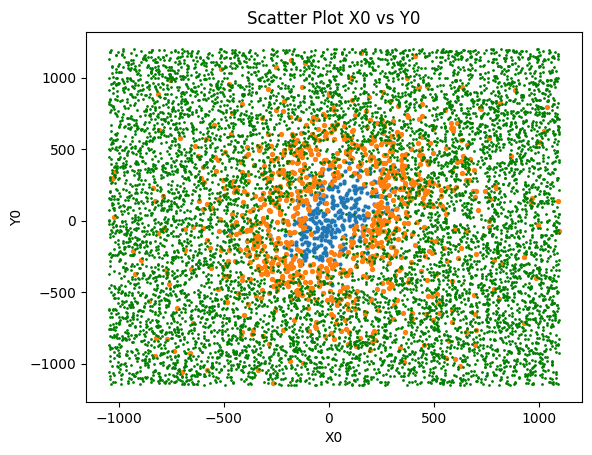

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Leer archivo (ajusta la ruta)
df = pd.read_csv("lightning_database.csv", sep=";")

# Crear figura
plt.figure()

# 1️⃣ Puntos con direct_strike = 0
df_ds0 = df[df["direc_strike"] == 1]
plt.scatter(df_ds0["X0"], df_ds0["Y0"],s=4)
df_ds1 = df[(df["direc_strike"] == 0) & (df["Rusck_maxV"] >= 50)]
plt.scatter(df_ds1["X0"], df_ds1["Y0"],s=8)
print(f"Number of points with direct strike = 1: {len(df_ds0)}")
# 2️⃣ Puntos con Rusck_maxV < 50
df_rusck = df[(df["Rusck_maxV"] < 50) & (df["direc_strike"] == 0)]
plt.scatter(df_rusck["X0"], df_rusck["Y0"],s=1,c='green')

# Etiquetas
plt.xlabel("X0")
plt.ylabel("Y0")
plt.title("Scatter Plot X0 vs Y0")

plt.show()

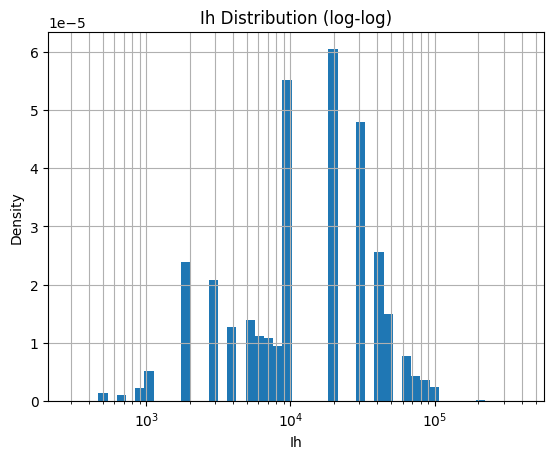

In [7]:
import numpy as np
Ih = df["Ih1"]
Ih = Ih[Ih > 0]

# Crear bins logarítmicos
bins = np.logspace(np.log10(Ih.min()),
                   np.log10(Ih.max()),
                   50)

plt.figure()

plt.hist(Ih, bins=bins, density=True)

plt.xscale("log")
plt.yscale("linear")

plt.xlabel("Ih")
plt.ylabel("Density")
plt.title("Ih Distribution (log-log)")
plt.grid(True, which="both")

plt.show()

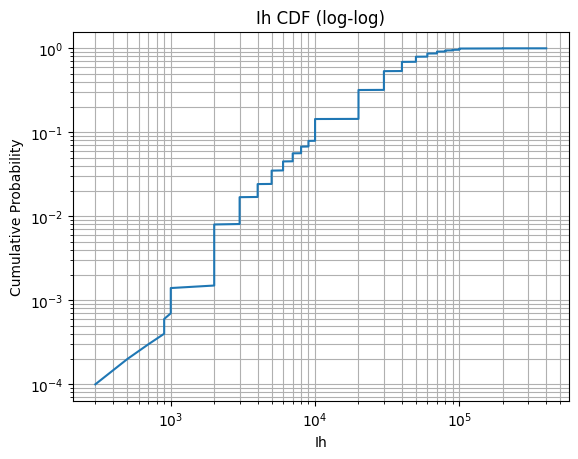

In [8]:
Ih_sorted = np.sort(Ih)

# Probabilidad acumulada empírica
N = len(Ih_sorted)
cdf = np.arange(1, N+1) / N

plt.figure()

plt.plot(Ih_sorted, cdf)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Ih")
plt.ylabel("Cumulative Probability")
plt.title("Ih CDF (log-log)")
plt.grid(True, which="both")

plt.show()

In [9]:
import ctypes
from ctypes import wintypes

def get_short_path(long_path):
    import ctypes
    from ctypes import wintypes
    buffer = ctypes.create_unicode_buffer(260)
    ctypes.windll.kernel32.GetShortPathNameW(
        long_path,
        buffer,
        260
    )
    return buffer.value

def run_atp(file:str):
    import subprocess
    import os

    file=get_short_path(file)
    print(f"Using short path: {file}")
    # Comando para ejecutar el programa externo
    current_dir = os.getcwd()
    #os.chdir("C:\\EMTP\\Solver\\")
    print(os.getcwd())
    #print(os.listdir())
    file_out = file.replace(".dat", ".lis")
    command = f"C:\\EMTP\\Solver\\tpbigm.exe BOTH {file} s -R"
    print(f"Running command: {command}")
    try:
        # Ejecutar el comando
        result = subprocess.run(command, 
                                shell=True, 
                                cwd=r"C:\\EMTP\\Solver\\",
                                check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
        print("Programa ejecutado exitosamente.")
        print("Salida:", result.stdout.decode())
    except subprocess.CalledProcessError as e:
        print("Error al ejecutar el programa.")
        print("Código de error:", e.returncode)
        print("Mensaje de error:", e.stderr.decode())

In [10]:
file="C:\\Users\\Ernesto Pérez\\Documents\\Git\\yaluk_network_lib\\lcc\\lcc_001.dat"
run_atp(file)

Using short path: C:\Users\ERNEST~1\DOCUME~1\Git\YALUK_~2\lcc\lcc_001.dat
c:\Users\Ernesto Pérez\Documents\Git\yaluk_network_lib
Running command: C:\EMTP\Solver\tpbigm.exe BOTH C:\Users\ERNEST~1\DOCUME~1\Git\YALUK_~2\lcc\lcc_001.dat s -R
Error al ejecutar el programa.
Código de error: 3
Mensaje de error: open: No such file or directory
apparent state: unit 46 named C:\Users\ERNEST,1\DOCUME,1\Git\YALUK_,                 .dbg
last format: list io
lately writing sequential formatted external IO

